# DDIM Sampling

DDIM can skip noise levels while using the same trained noise predictor. Compare twelve deterministic steps with forty-eight stochastic DDPM steps from the same initial noise.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Forward process

The cosine schedule gradually removes structure. A time-conditioned network predicts the noise added to a clean training point.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from gallery.neural import seed_cpu
from gallery.diffusion import (
    NoisePredictor,
    NoiseSchedule,
    train_noise,
    heldout_noise,
    sample,
    distribution_scores,
    training_bandwidth,
)

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

## Learn the score through noise prediction

The standardiser and kernel bandwidth use training points. Independently generated moons supply the reference distribution.

In [3]:
seed_cpu()
train, _ = make_moons(1800, noise=0.055, random_state=17)
reference, _ = make_moons(450, noise=0.055, random_state=73)
split_ref, _ = make_moons(450, noise=0.055, random_state=117)
scaler = StandardScaler().fit(train)
X = torch.tensor(scaler.transform(train), dtype=torch.float32)
reference = scaler.transform(reference)
split_ref = scaler.transform(split_ref)
schedule = NoiseSchedule(48)
net = NoisePredictor(2, 96)
history = train_noise(net, schedule, X, updates=1700)
heldout_noise(net, schedule, torch.tensor(reference, dtype=torch.float32))
bandwidth = training_bandwidth(X.numpy())
initial = torch.randn((450, 2), generator=torch.Generator().manual_seed(89))

Held-out epsilon MSE 0.454 | zero-predictor MSE 0.994


## Draw new points

The same Gaussian starting points are used across samplers. Smaller MMD² and sliced Wasserstein distance indicate closer sample distributions.

Independent real sample: MMD² 0.0000 | sliced Wasserstein 0.023
DDPM, 48 steps: MMD² 0.0014 | sliced Wasserstein 0.085
DDIM, 12 steps: MMD² 0.0115 | sliced Wasserstein 0.177


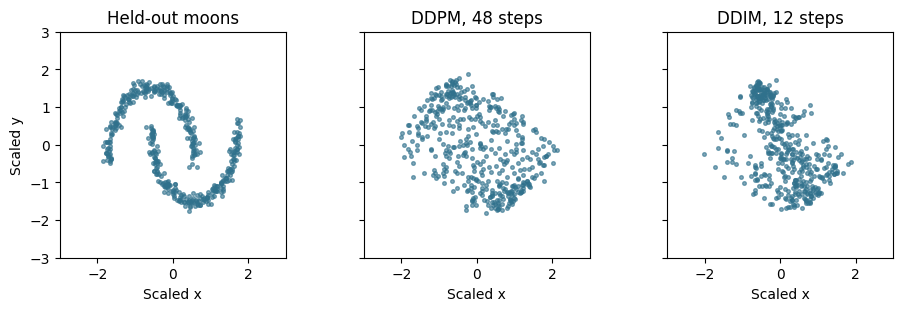

In [4]:
ancestral = sample(net, schedule, initial, "ddpm", limit=2.6)
generated = sample(net, schedule, initial, "ddim", limit=2.6, count=12)
sets = [
    ("Independent real sample", split_ref),
    ("DDPM, 48 steps", ancestral),
    ("DDIM, 12 steps", generated),
]
panels = [
    ("Held-out moons", reference),
    ("DDPM, 48 steps", ancestral),
    ("DDIM, 12 steps", generated),
]

for title, cloud in sets:
    mmd, sw = distribution_scores(reference, cloud, bandwidth)
    print(f"{title}: MMD² {mmd:.4f} | sliced Wasserstein {sw:.3f}")
fig, axes = plt.subplots(1, 3, figsize=(9.4, 3), sharex=True, sharey=True, constrained_layout=True)
for ax, (label, cloud) in zip(axes, panels):
    ax.scatter(*cloud.T, s=7, alpha=0.6, color="#30718c")
    ax.set(xlim=(-3, 3), ylim=(-3, 3), aspect="equal", title=label, xlabel="Scaled x")
axes[0].set_ylabel("Scaled y")
plt.show()

## Reading the result

An independently drawn real sample gives a finite-sample reference for both distances. The spaces between the crescents are worth inspecting even when a global score is small.

## References

[Ho, Jain and Abbeel, Denoising Diffusion Probabilistic Models (2020)](https://arxiv.org/abs/2006.11239)

[Song, Meng and Ermon, Denoising Diffusion Implicit Models (2020)](https://arxiv.org/abs/2010.02502)

[Nichol and Dhariwal, Improved Denoising Diffusion Probabilistic Models (2021)](https://arxiv.org/abs/2102.09672)

[scikit-learn, make_moons](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html)

[Noise schedule, training objective and reverse samplers](../../gallery/diffusion.py)